<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/Breast_Cancer_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer


In [ ]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target names:", data.target_names)
print("\nFirst five rows:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (569, 30)
Target names: ['malignant' 'benign']

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean frac

In [ ]:
print(X.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (455, 30)
Testing features: (114, 30)

Training target proportions:
target
1    0.626
0    0.374
Name: proportion, dtype: float64

Testing target proportions:
target
1    0.632
0    0.368
Name: proportion, dtype: float64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier

models = {"Logistic regresssion": Pipeline(steps = [("imputer",SimpleImputer(strategy = "median")),
                                                    ("scaler",StandardScaler()),
                                                    ("model",LogisticRegression(max_iter=2000))]),

          "Decision Tree":Pipeline (steps = [("imputer",SimpleImputer(strategy="median")),
                                             ("model",DecisionTreeClassifier(random_state=42))]),


          "Random Forest" : Pipeline(steps = [("imputer",SimpleImputer(strategy = "median")),
                                              ("model",RandomForestClassifier(n_estimators=100,
                                                                              random_state=42,
                                                                              n_jobs = -1))]),

          "Gradient Boosting": Pipeline (steps =[("imputer",SimpleImputer(strategy = "median")),
                                                 ("model",GradientBoostingClassifier(random_state=42))])

}
for name,model in models.items():
  model.fit(X_train,y_train)


In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

results = []
confusion_matrices = {}

for name, model in models.items():

    # Predictions on training and testing data
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Probability that the target is malignant (class 1)
    test_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1": f1_score(y_test, test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_prob)
    })

    confusion_matrices[name] = confusion_matrix(y_test, test_pred)

comparison = pd.DataFrame(results).round(3)

print(comparison.to_string(index=False))

for name, matrix in confusion_matrices.items():
    print(f"\n{name}")
    print("Rows = actual; columns = predicted")
    print(matrix)


               Model  Train Accuracy  Test Accuracy  Precision  Recall    F1  ROC-AUC
Logistic regresssion           0.989          0.982      0.986   0.986 0.986    0.995
       Decision Tree           1.000          0.912      0.956   0.903 0.929    0.916
       Random Forest           1.000          0.956      0.959   0.972 0.966    0.994
   Gradient Boosting           1.000          0.956      0.947   0.986 0.966    0.991

Logistic regresssion
Rows = actual; columns = predicted
[[41  1]
 [ 1 71]]

Decision Tree
Rows = actual; columns = predicted
[[39  3]
 [ 7 65]]

Random Forest
Rows = actual; columns = predicted
[[39  3]
 [ 2 70]]

Gradient Boosting
Rows = actual; columns = predicted
[[38  4]
 [ 1 71]]


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = models["Random Forest"]

param_grid = {
    "model__n_estimators":[100,200],
    "model__max_depth":[None,5,10],
    "model__min_samples_leaf":[1,2,5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid ,
    scoring = "recall",
    cv= 5
)

grid_search.fit(X_train,y_train)

print("best parameter",grid_search.best_params_)
print("Best cv recall",grid_search.best_score_,3)

best_rf = grid_search.best_estimator_


best parameter {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best cv recall 0.968421052631579 3


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

candidates = {
    "Original Random Forest": models["Random Forest"],
    "Tuned Random Forest": best_rf
}

comparison = []

for name, model in candidates.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

tuning_comparison = pd.DataFrame(comparison).round(3)
print(tuning_comparison.to_string(index=False))


                 Model  Accuracy  Precision  Recall    F1  ROC-AUC
Original Random Forest     0.956      0.959   0.972 0.966    0.994
   Tuned Random Forest     0.956      0.959   0.972 0.966    0.994


Top 10 features:
worst area              0.1400
worst concave points    0.1295
worst radius            0.0977
mean concave points     0.0909
worst perimeter         0.0722
mean perimeter          0.0696
mean radius             0.0687
mean concavity          0.0576
mean area               0.0492
worst concavity         0.0343
dtype: float64


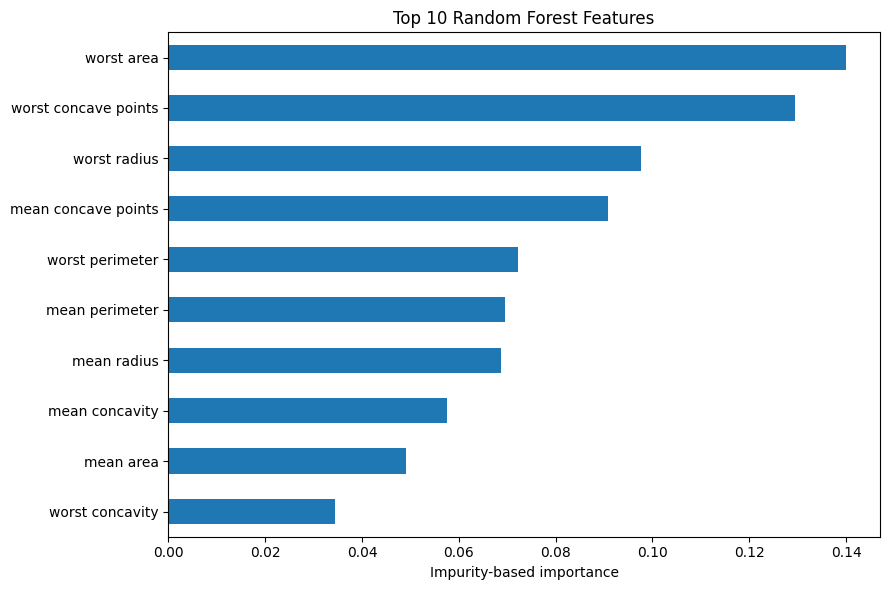

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

rf_estimator = best_rf.named_steps["model"]

feature_importance = pd.Series(
    rf_estimator.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 features:")
print(feature_importance.head(10).round(4))

feature_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Top 10 Random Forest Features"
)

plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()